# 03 — Protocole expérimental

**Objectif** : définir **comment les modèles seront entraînés, réglés et évalués**, et justifier ce choix.

Un bon protocole doit respecter quatre exigences :
1. **Réalisme temporel** : en production, un modèle est entraîné sur le passé et appliqué au futur. L'évaluation doit reproduire cette situation.
2. **Absence de fuite** : aucune information du jeu de test ne doit influencer l'entraînement ou les choix de modélisation.
3. **Représentativité** : le jeu de test doit ressembler aux conditions normales d'exploitation, sinon les métriques (et le seuil de décision choisi) ne veulent rien dire.
4. **Effectifs suffisants** : assez de fraudes dans chaque jeu pour des métriques stables.

L'EDA a montré que le taux de fraude **n'est pas stationnaire**, ce qui rend les exigences 1 et 3 difficiles à concilier.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src.config import RANDOM_STATE, TRAIN_LAST_DAY, VAL_LAST_DAY, TEST_LAST_DAY
from src.data import load_data
from src.split import (filter_fraud_types, step_to_day, temporal_split,
                       check_no_temporal_overlap, summarize_splits, save_splits)
from src.viz import set_style, save_fig, COLOR_LEGIT, COLOR_FRAUD, TEXT_SECONDARY, GRID_COLOR

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Périmètre : TRANSFER et CASH_OUT

Conformément à H1, seuls les types `TRANSFER` et `CASH_OUT` contiennent de la fraude. Les autres types seraient, en production, acceptés **sans scoring** : le modèle ne sera entraîné et évalué que sur ce périmètre.

In [2]:
df = filter_fraud_types(load_data())
df["jour"] = step_to_day(df["step"])
print(f"{len(df):,} transactions, {df['isFraud'].sum():,} fraudes ({df['isFraud'].mean():.3%})")

2,770,409 transactions, 8,213 fraudes (0.296%)


## 2. Deux régimes d'activité

In [3]:
daily = df.groupby("jour").agg(n=("isFraud", "size"), fraudes=("isFraud", "sum"))
daily["taux_pct"] = daily["fraudes"] / daily["n"] * 100
# Un jour est « normal » si son volume dépasse 25 % du volume quotidien maximal
daily["regime"] = np.where(daily["n"] >= 0.25 * daily["n"].max(), "normal", "anormal")
daily.T

jour,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
n,250180,202388,1804,7145,3586,195729,185960,196933,181672,171785,...,21355,20702,13882,24549,5466,3718,5680,23365,5057,282
fraudes,265,305,306,272,244,230,280,270,259,274,...,252,220,276,236,280,276,254,262,264,282
taux_pct,0.106,0.151,16.962,3.807,6.804,0.118,0.151,0.137,0.143,0.160,...,1.180,1.063,1.988,0.961,5.123,7.423,4.472,1.121,5.220,100.000
regime,normal,normal,anormal,anormal,anormal,normal,normal,normal,normal,normal,...,anormal,anormal,anormal,anormal,anormal,anormal,anormal,anormal,anormal,anormal


In [4]:
regimes = daily.groupby("regime").agg(jours=("n", "size"), n=("n", "sum"), fraudes=("fraudes", "sum"))
regimes["pct_volume"] = regimes["n"] / regimes["n"].sum() * 100
regimes["pct_fraudes"] = regimes["fraudes"] / regimes["fraudes"].sum() * 100
regimes["taux_fraude_pct"] = regimes["fraudes"] / regimes["n"] * 100
regimes

,jours,n,fraudes,pct_volume,pct_fraudes,taux_fraude_pct
regime,,,,,,
anormal,17,169194,4456,6.107,54.255,2.634
normal,14,2601215,3757,93.893,45.745,0.144


On distingue nettement deux régimes :
- **normal** (jours 0-1 et 5-16) : ~94 % du volume, taux de fraude stable autour de **0,15 %** ;
- **anormal** (jours 2-4 et 17-30) : l'activité légitime du simulateur s'effondre alors que la fraude continue au même rythme (~260 par jour). Ces jours ne représentent que ~6 % du volume mais **plus de la moitié des fraudes**, avec des taux de 1 % à 100 % (le jour 30 ne contient que des fraudes).

Le régime anormal est un **artefact du simulateur**, pas un phénomène métier : aucun opérateur ne voit son activité légitime divisée par 50 du jour au lendemain.

## 3. Comparaison de stratégies de découpage

On compare quatre stratégies selon les exigences listées en introduction.

In [5]:
def describe(name, parts):
    row = {"stratégie": name}
    for split, part in parts.items():
        row[f"taux {split} (%)"] = part["isFraud"].mean() * 100
    row["fraudes test"] = int(parts["test"]["isFraud"].sum())
    return row

rows = []

# A. Aléatoire stratifié 70/15/15 (ignore le temps)
train_a, rest = train_test_split(df, test_size=0.30, stratify=df["isFraud"], random_state=RANDOM_STATE)
val_a, test_a = train_test_split(rest, test_size=0.50, stratify=rest["isFraud"], random_state=RANDOM_STATE)
rows.append(describe("A. Aléatoire stratifié", {"train": train_a, "val": val_a, "test": test_a}))

# B. Temporel 70/15/15 en volume de transactions
q70, q85 = df["step"].quantile([0.70, 0.85])
rows.append(describe("B. Temporel 70/15/15 (volume)", {
    "train": df[df["step"] <= q70], "val": df[(df["step"] > q70) & (df["step"] <= q85)],
    "test": df[df["step"] > q85]}))

# C. Temporel en jours : 0-20 / 21-25 / 26-30
rows.append(describe("C. Temporel 21/5/5 jours", {
    "train": df[df["jour"] <= 20], "val": df[df["jour"].between(21, 25)], "test": df[df["jour"] >= 26]}))

# D. Retenu : temporel sur le régime normal + jeu de drift
splits = temporal_split(df)
rows.append(describe("D. Temporel régime normal (retenu)", splits))

comparison = pd.DataFrame(rows).set_index("stratégie")
comparison

,taux train (%),taux val (%),taux test (%),fraudes test,taux drift (%)
stratégie,,,,,
A. Aléatoire stratifié,0.296,0.296,0.296,1232,NaN
B. Temporel 70/15/15 (volume),0.187,0.136,0.983,4010,NaN
C. Temporel 21/5/5 jours,0.212,1.471,3.512,1338,NaN
D. Temporel régime normal (retenu),0.183,0.144,0.163,570,2.320


**Analyse des stratégies**

| Stratégie | Réalisme temporel | Représentativité du test | Verdict |
|---|---|---|---|
| **A. Aléatoire stratifié** | ❌ Le modèle apprend sur des transactions **postérieures** à celles du test | ✅ Taux identiques partout | Rejetée : évaluation optimiste et irréaliste |
| **B. Temporel 70/15/15 en volume** | ✅ | ❌ Le test mélange les deux régimes : taux de fraude ~5× plus élevé qu'à l'entraînement | Rejetée : métriques et seuil faussés |
| **C. Temporel en jours** | ✅ | ❌ Test entièrement dans la période anormale : taux ~17× plus élevé | Rejetée : le test ne ressemble à rien de réaliste |
| **D. Temporel sur le régime normal** | ✅ | ✅ Taux comparables entre train, val et test | **Retenue** |

Avec B ou C, la précision mesurée sur le test serait artificiellement **gonflée** (une alerte a beaucoup plus de chances d'être une fraude quand 3 % des transactions sont frauduleuses que quand 0,15 % le sont), et le seuil choisi sur la validation serait inadapté.

## 4. Protocole retenu

In [6]:
check_no_temporal_overlap(splits)
summary = summarize_splits(splits)
summary

,jours,n_transactions,pct_transactions,n_fraudes,taux_fraude_pct
train,0–12,1917584,69.217,3511,0.183
val,13–14,346348,12.502,498,0.144
test,15–16,349818,12.627,570,0.163
drift,17–30,156659,5.655,3634,2.320


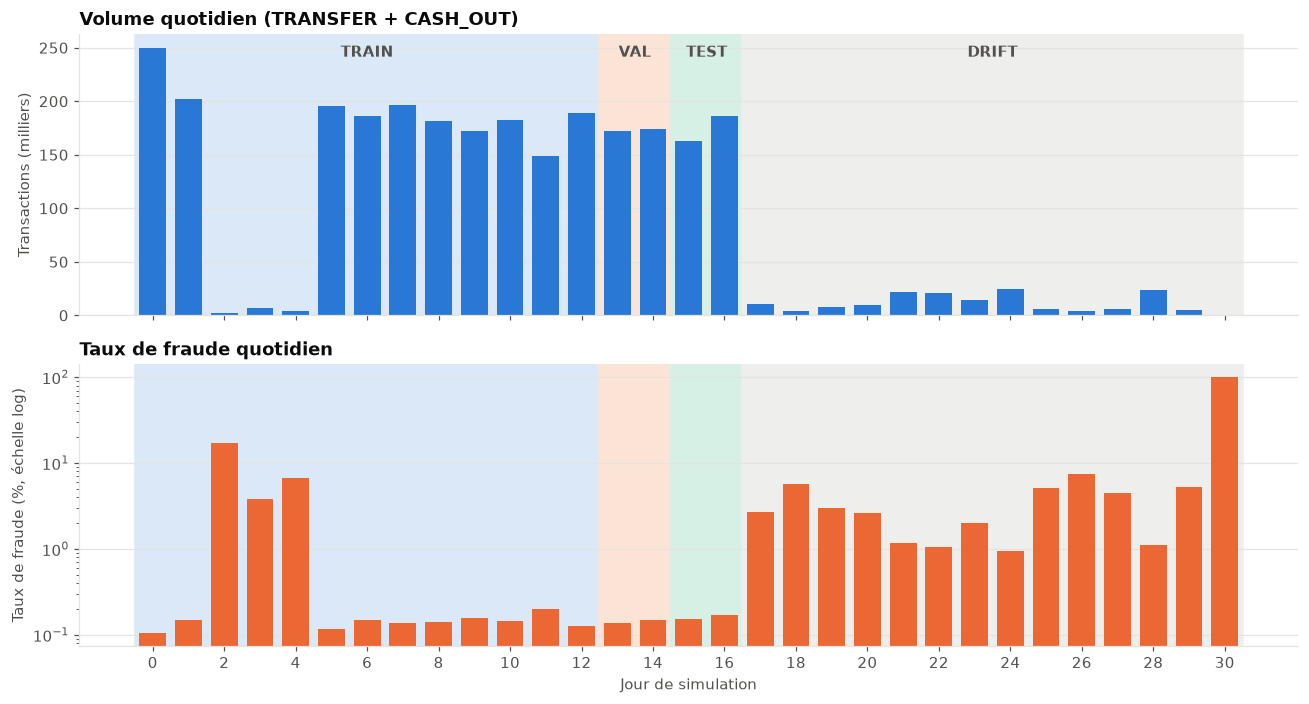

In [7]:
colors = {"train": "#dbe8f8", "val": "#fbe3d6", "test": "#d7f0e5", "drift": "#eeeeec"}
bounds = {"train": (-0.5, TRAIN_LAST_DAY + 0.5), "val": (TRAIN_LAST_DAY + 0.5, VAL_LAST_DAY + 0.5),
          "test": (VAL_LAST_DAY + 0.5, TEST_LAST_DAY + 0.5), "drift": (TEST_LAST_DAY + 0.5, daily.index.max() + 0.5)}

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax in axes:
    for name, (lo, hi) in bounds.items():
        ax.axvspan(lo, hi, color=colors[name], zorder=0)
    ax.grid(axis="x", visible=False)

axes[0].bar(daily.index, daily["n"] / 1e3, color=COLOR_LEGIT, width=0.75)
axes[0].set_ylabel("Transactions (milliers)")
axes[0].set_title("Volume quotidien (TRANSFER + CASH_OUT)")
for name, (lo, hi) in bounds.items():
    axes[0].text((lo + hi) / 2, axes[0].get_ylim()[1] * 0.92, name.upper(), ha="center",
                 fontweight="bold", color=TEXT_SECONDARY)

axes[1].bar(daily.index, daily["taux_pct"], color=COLOR_FRAUD, width=0.75)
axes[1].set_yscale("log")
axes[1].set_ylabel("Taux de fraude (%, échelle log)")
axes[1].set_xlabel("Jour de simulation")
axes[1].set_title("Taux de fraude quotidien")
axes[1].set_xticks(range(0, daily.index.max() + 1, 2))

fig.tight_layout()
save_fig(fig, "03_protocole_split_temporel")
plt.show()

### Rôle de chaque jeu

| Jeu | Jours | Rôle | Règle d'usage |
|---|---|---|---|
| **train** | 0 – 12 | Apprentissage des modèles et du prétraitement | Seul jeu sur lequel on apprend (y compris le rééquilibrage) |
| **val** | 13 – 14 | Comparaison des modèles, réglage des hyperparamètres, **choix du seuil** | Peut être utilisé autant que nécessaire |
| **test** | 15 – 16 | **Évaluation finale** du modèle retenu | Utilisé **une seule fois**, à la toute fin |
| **drift** | 17 – 30 | **Test de robustesse** : comportement du modèle quand la distribution change | Analyse complémentaire, jamais utilisé pour choisir |

**Remarques méthodologiques**
- Le jeu train inclut les jours 2-4 (régime anormal). On les conserve : ils appartiennent au passé et apportent des fraudes supplémentaires. Leur influence sur le taux global reste faible.
- On renonce à entraîner sur les fraudes des jours 17-30. C'est un **compromis assumé** : on perd des exemples de fraude, mais on gagne une évaluation **crédible**. Le train contient tout de même plus de 3 500 fraudes.
- Le jeu **drift** permet de répondre à une vraie question de production : *le modèle reste-t-il fiable si la proportion de fraudes change brutalement ?* On s'attend à ce que le rappel soit stable (le modèle reconnaît les mêmes fraudes) mais à ce que la précision augmente mécaniquement (plus de fraudes parmi les alertes).
- Pour le réglage des hyperparamètres (Phase 7), une validation croisée **temporelle** (`TimeSeriesSplit`) au sein du train pourra compléter le jeu de validation.

## 5. Sauvegarde des jeux

Les jeux sont sauvegardés une fois pour toutes : tous les notebooks suivants chargeront **exactement les mêmes données** via `load_split()`.

In [8]:
to_save = {name: part.drop(columns="jour") for name, part in splits.items()}
paths = save_splits(to_save)
for p in paths:
    print(f"{p.relative_to(ROOT)}  ({p.stat().st_size / 1024**2:,.1f} Mo)")

data\processed\splits\train.parquet  (74.6 Mo)
data\processed\splits\val.parquet  (14.5 Mo)
data\processed\splits\test.parquet  (14.7 Mo)
data\processed\splits\drift.parquet  (7.2 Mo)


## 6. Conclusions

- **Découpage retenu** : temporel, en quatre jeux (train 0-12, val 13-14, test 15-16, drift 17-30), défini dans `src/config.py` et implémenté dans `src/split.py`.
- **Justification** : c'est la seule stratégie testée qui respecte à la fois l'ordre temporel et la représentativité du jeu de test. Les découpages temporels naïfs produiraient un test au taux de fraude 5 à 17 fois supérieur à celui de l'entraînement.
- **Garanties** : absence de chevauchement temporel vérifiée par un test automatique ; jeu de test réservé à l'évaluation finale ; jeu de drift dédié à l'analyse de robustesse.

**Étape suivante** : Phase 5, feature engineering à partir des variables identifiées en EDA, implémenté sous forme de pipeline scikit-learn appris uniquement sur le train.